In [44]:
BANDS_TO_USE = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']
save_dir_imgs = "./dataset/test/imgs"
save_dir_masks = "./dataset/test/masks/"

# **Global ML**

Illegal mines: gather locations and timestamps, download multispectral images with ee

In [45]:
import os
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import rioxarray
import fiona

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

import numpy as np

In [47]:
gpkg_path = './data/Global_ML/mining_area_data.gpkg'
print(f"layers:\n\t{fiona.listlayers(gpkg_path)}")

# Load the tiles table (contains the s2_tile_name)
gdf_tiles = gpd.read_file(gpkg_path, layer='tiles')
print(f"\ntiles table:\t{gdf_tiles.columns}")

# Load the validated polygons (or whichever polygon layer you intend to use)
gdf_polygons = gpd.read_file(gpkg_path, layer='test_polygons_validated') 
# Split the giant MULTIPOLYGON into individual mine polygons
gdf_polygons = gdf_polygons.explode(index_parts=False).reset_index(drop=True)
print(f"\npolygons table:\t{gdf_polygons.columns}")

# Merge them based on tile_id
gdf = gdf_polygons.merge(gdf_tiles[['tile_id', 's2_tile_id']], on='tile_id', how='left')

# apply projections
gdf_metric = gdf.to_crs(epsg=3857) 
gdf_buffered_metric = gdf_metric.copy()
gdf_buffered_metric['geometry'] = gdf_metric.geometry.centroid.buffer(600) # buffer of 600 meters around the centroid of each polygon
gdf_buffered_metric['geometry'] = gdf_buffered_metric['geometry'].envelope # cap the bounding box (makes it a perfect square)
gdf_buffered = gdf_buffered_metric.to_crs(epsg=4326)

print(f"\nMerged table:\t{gdf_buffered.columns}")

layers:
	['maus_polygons', 'tang_polygons', 'maus_bboxes', 'tang_bboxes', 'preferred_polygons', 'preferred_bboxes', 'tiles', 'test_polygons_validated']

tiles table:	Index(['tile_id', 's2_tile_id', 'source_dataset', 'preferred_dataset',
       'minetype1', 'minetype2', 'comment', 'timestamp', 'split', 'geometry'],
      dtype='object')

polygons table:	Index(['tile_id', 'geometry'], dtype='object')

Merged table:	Index(['tile_id', 'geometry', 's2_tile_id'], dtype='object')


In [48]:
n_rois = len(gdf_buffered)

# download the mines multispectral images
for index, row in gdf_buffered.iterrows():
    minx, miny, maxx, maxy = row.geometry.bounds    # bounding box from the polygon geometry
    roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])
    
    s2_tile_id = row['s2_tile_id']
    print(f"\nProcessing ROI {index}/{n_rois-1} - Tile: {s2_tile_id}")

    try:
        # --------------- fetch the image
        parts = s2_tile_id.split('_')
        date_str = parts[2][:8]
        start_date = f"{date_str[:4]}-{date_str[4:6]}-{date_str[6:]}"
        end_date = (pd.to_datetime(start_date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        mgrs_tile = parts[4][1:]
        # print(f"\nProcessing ROI {index} - Tile: {s2_tile_id}\n\tDate: {start_date}, MGRS: {mgrs_tile}")
        
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filter(ee.Filter.eq('MGRS_TILE', mgrs_tile)))
        
        if s2_collection.size().getInfo() == 0:
            print(f"Image {s2_tile_id} not found in Earth Engine.")
            continue

        s2_image = s2_collection.first().select(BANDS_TO_USE)
        
        # --------------- download the images (from the roi at the specified time interval) into the RAM
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs="EPSG:3857", progress=False)

        # --------------- convert data to numpy
        # stack bands
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)    # (Channels, H, W)
        # Clean up any missing edge pixels and scale the Sentinel-2 L2A values
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- rasterize the mask
        ds = ds.rio.write_crs("EPSG:3857") # Explicitly register CRS to prevent rioxarray crashes
        transform = ds.rio.transform()
        out_shape = (img_array.shape[1], img_array.shape[2]) # (H, W)

        # Burn the original unbuffered polygon into the mask
        original_polygon = gdf_metric.loc[index].geometry
        mask_array = rasterize(
            [(original_polygon, 1)], # Label the polygon area as 1
            out_shape=out_shape,
            transform=transform,
            fill=0, # Background is 0
            dtype='uint8'
        )

        # --------------- force 120x120 shape to guarantee compatibility with ben-ge-8k
        TARGET_SIZE = 120
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]


        if img_array.max() == 0:
            print(f"Skipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"Skipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        # label = "anomaly" if mask_array.sum() >= 5 else "normal"
        label = "anomaly"

        np.save(os.path.join(save_dir_imgs, f"mines_img_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"mines_img_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping ROI {index}, error: {e}")
        continue


Processing ROI 0/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 5 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 6/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing R

# **hls burn scars**
Burn scars: gather locations and timestamps, download multispectral images with ee

In [ ]:
import os
import glob
import rasterio
from rasterio.warp import transform_bounds
import pandas as pd
from datetime import datetime, timedelta

import pandas as pd

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

In [ ]:
def create_metadata_csv(dataset_dir, output_csv):
    """
    Extracts dates and geographic bounds from subsetted HLS .tif files.
    """
    data = []
    
    # Find all merged images (ignoring the masks for the metadata extraction)
    search_pattern = os.path.join(dataset_dir, '**', '*_merged.tif')
    tif_files = glob.glob(search_pattern, recursive=True)
    
    print(f"Found {len(tif_files)} files. Extracting metadata...")
    
    for filepath in tif_files:
        filename = os.path.basename(filepath)
        
        # Parse filename: subsetted_512x512_HLS.S30.T10SEH.2018190.v1.4_merged.tif
        parts = filename.split('.')
        tile_id = parts[2]       # e.g., T10SEH
        year_doy = parts[3]      # e.g., 2018190 (Year 2018, Day of Year 190)
        
        # Convert Year+DayOfYear to standard YYYY-MM-DD
        date_obj = datetime.strptime(year_doy, '%Y%j')
        date_str = date_obj.strftime('%Y-%m-%d')
        
        # Open the TIF to extract exact spatial bounds
        with rasterio.open(filepath) as src:
            bounds = src.bounds
            crs = src.crs
            
            # GEE needs standard EPSG:4326 (Lat/Lon)
            min_lon, min_lat, max_lon, max_lat = transform_bounds(crs, 'EPSG:4326', *bounds)
            
        data.append({
            'filename': filename,
            'mask_filename': filename.replace('_merged.tif', '.mask.tif'),
            'tile_id': tile_id,
            'date': date_str,
            'min_lon': min_lon,
            'min_lat': min_lat,
            'max_lon': max_lon,
            'max_lat': max_lat
        })
        
    df = pd.DataFrame(data)
    df.to_csv(output_csv, index=False)
    print(f"Saved metadata to {output_csv}")

# Run the extraction
create_metadata_csv('path/to/hls_burn_scars', 'burn_scars_metadata.csv')

In [ ]:
def download_gee_images_from_csv(csv_path, output_dir, bands_to_use):
    df = pd.read_csv(csv_path)
    
    for index, row in df.iterrows():
        # 1. Define Geometry
        roi = ee.Geometry.Rectangle([row['min_lon'], row['min_lat'], row['max_lon'], row['max_lat']])
        
        # 2. Define Time Window (Exact date to Date + 1 day)
        t_start = row['date']
        t_end = (datetime.strptime(t_start, '%Y-%m-%d') + timedelta(days=1)).strftime('%Y-%m-%d')
        
        # 3. Query GEE for Sentinel-2 Level-2A
        s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
              .filterBounds(roi)
              .filterDate(t_start, t_end)
              .select(bands_to_use))
              
        # Check if an image actually exists for that exact day
        if s2.size().getInfo() == 0:
            print(f"Skipping {row['filename']}: No S2 image found in GEE for {t_start}.")
            continue
            
        try:
            # 4. Download and save locally
            print(f"Downloading data for {row['filename']} on {t_start}...")
            s2_mosaic = s2.mosaic().set('system:time_start', ee.Date(t_start).millis())
            s2_collection = ee.ImageCollection([s2_mosaic])

            ts = wxee.TimeSeries(s2_collection)
            
            # Download as an xarray dataset (scale=10 for 10m resolution)
            ds = ts.wx.to_xarray(region=roi, scale=10, progress=False)
            
            # Save it locally as a NetCDF or convert to Numpy/TIF
            out_filename = "burnscars_" + row['filename'].replace('.tif', '_13bands.nc')
            out_file = os.path.join(output_dir, out_filename)
            ds.to_netcdf(out_file)
            
        except Exception as e:
            print(f"Error downloading {row['filename']}: {e}")

download_gee_images_from_csv('burn_scars_metadata.csv', save_dir, BANDS_TO_USE)

# **Validating**

Loaded ROI 0
Image shape: (12, 120, 120), Min: 0.0136, Max: 0.5269
Mask shape: (120, 120), Unique values: [0 1]


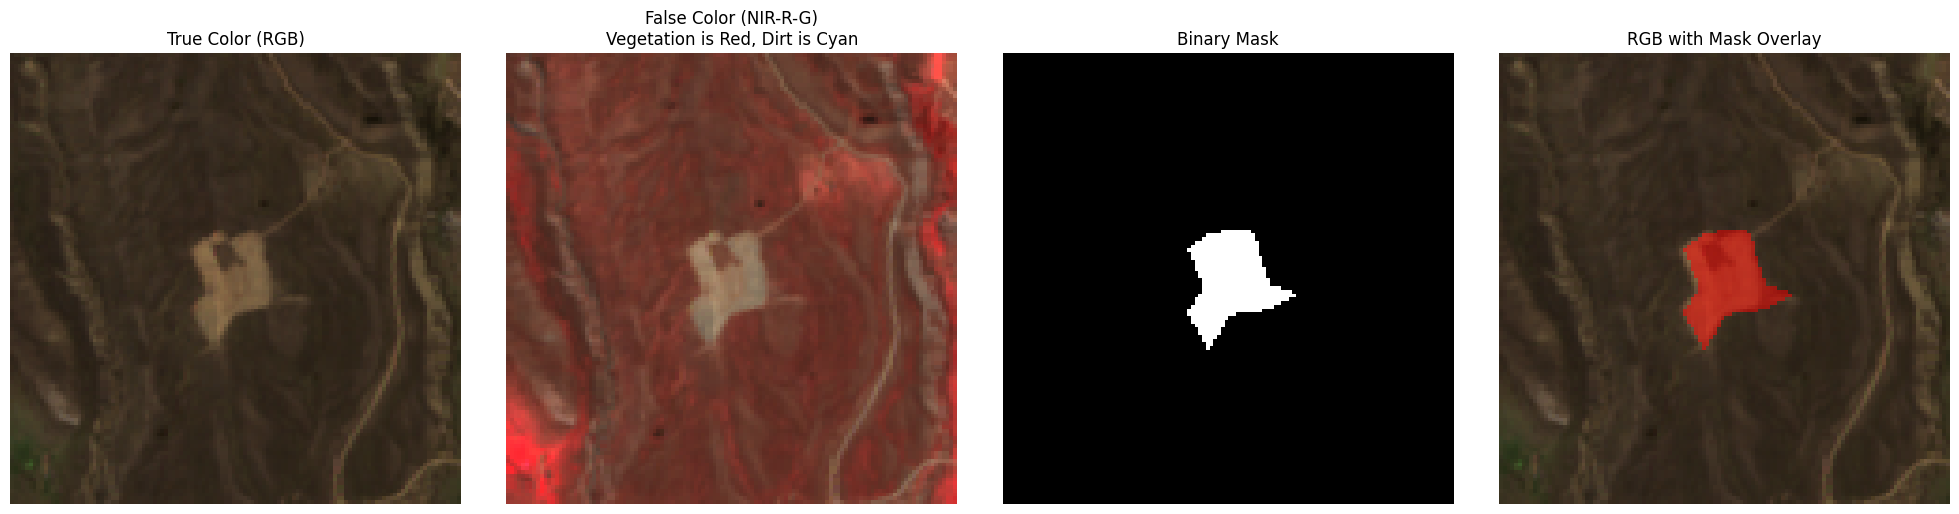

Loaded ROI 1
Image shape: (12, 120, 120), Min: 0.0194, Max: 0.3955
Mask shape: (120, 120), Unique values: [0 1]


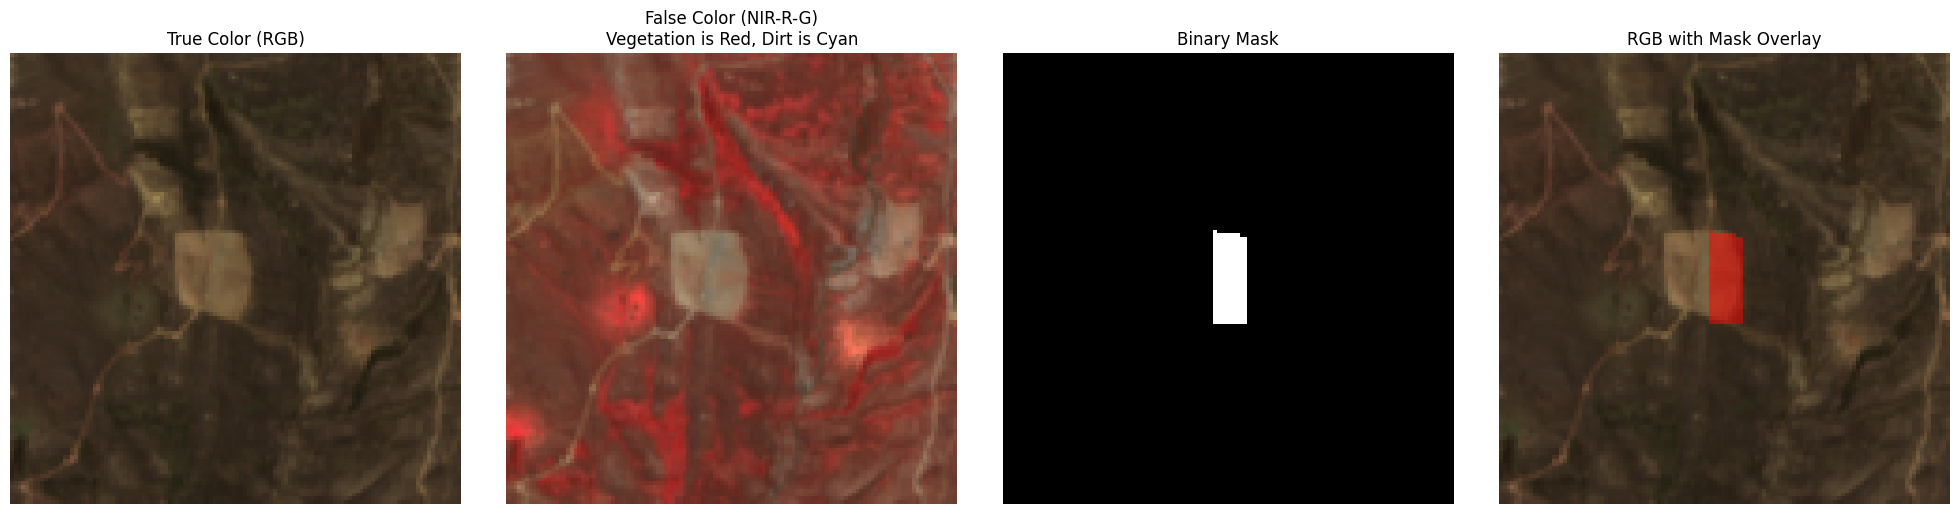

Loaded ROI 2
Image shape: (12, 120, 120), Min: 0.0000, Max: 0.3896
Mask shape: (120, 120), Unique values: [0 1]


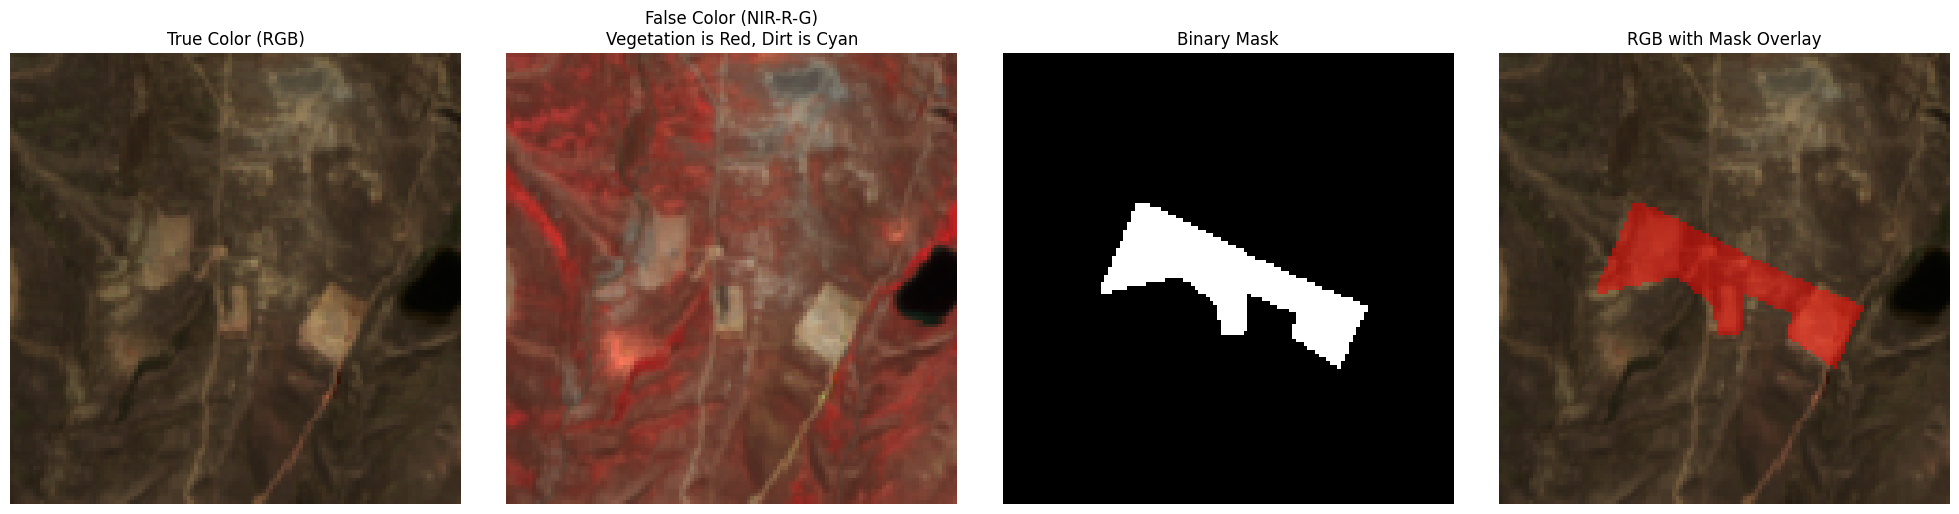

Loaded ROI 3
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.4372
Mask shape: (120, 120), Unique values: [0 1]


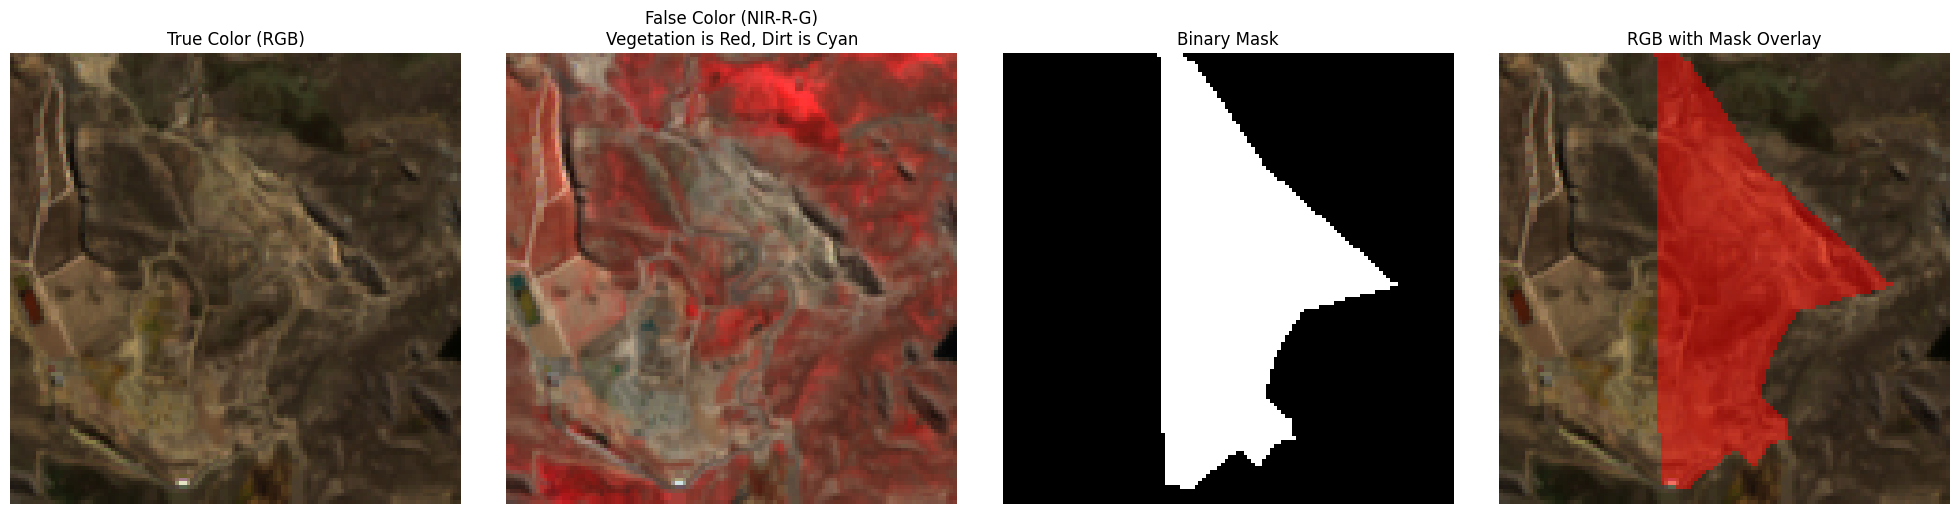

Loaded ROI 4
Image shape: (12, 120, 120), Min: 0.0001, Max: 0.4473
Mask shape: (120, 120), Unique values: [0 1]


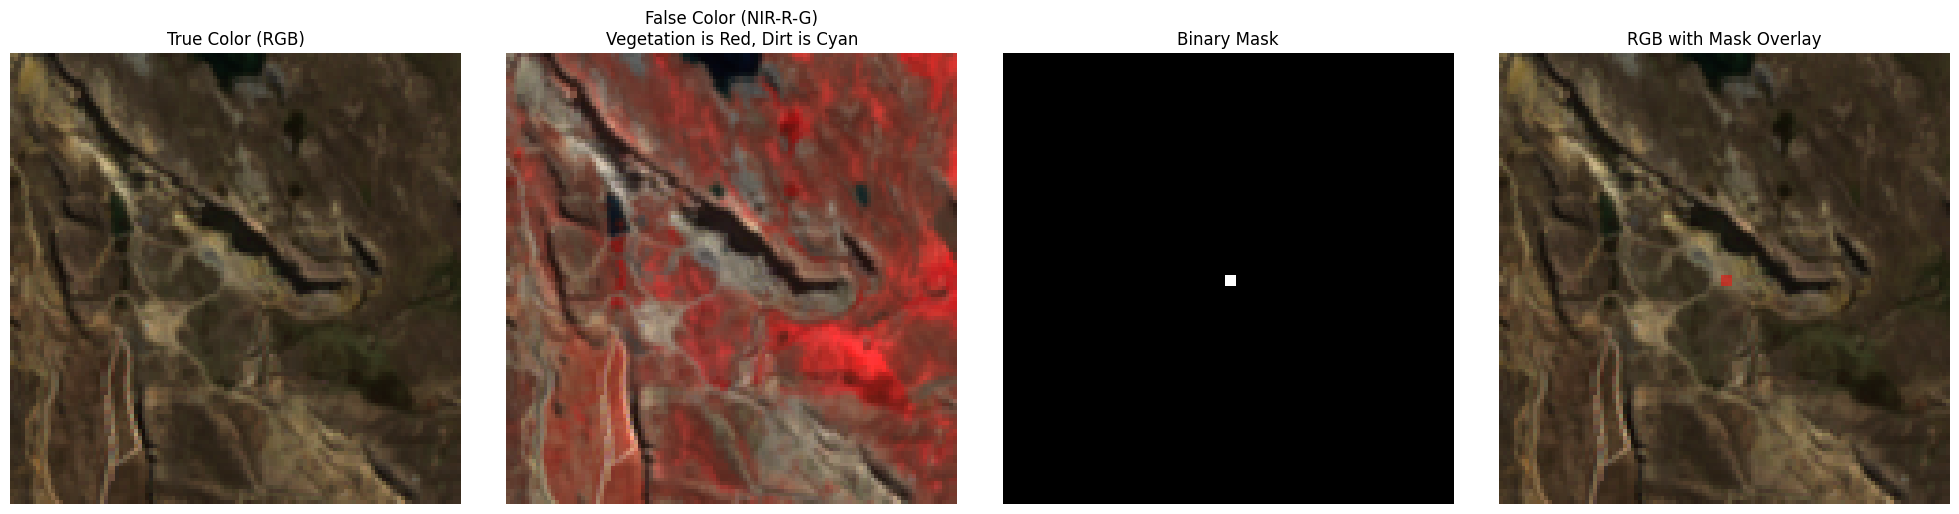

In [61]:
import os
import numpy as np
import matplotlib.pyplot as plt

def validate_mine_patch(index, img_dir="./dataset/test/imgs", mask_dir="./dataset/test/masks/"):
    # File paths
    img_path = os.path.join(img_dir, f"mines_img_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"mines_img_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    rgb_bright = np.clip(rgb * 2.5, 0, 1)

    # Extract False Color Infrared (NIR, Red, Green: B8, B4, B3 -> Indices 7, 3, 2)
    # This makes vegetation appear bright red, and bare earth/mines appear cyan/grey
    fcc = img_array[[7, 3, 2], :, :].transpose(1, 2, 0)
    fcc_bright = np.clip(fcc * 2.5, 0, 1)

    # Setup the plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_bright)
    axes[0].set_title("True Color (RGB)")
    axes[0].axis("off")

    # 2. False Color
    axes[1].imshow(fcc_bright)
    axes[1].set_title("False Color (NIR-R-G)\nVegetation is Red, Dirt is Cyan")
    axes[1].axis("off")

    # 3. Mask Only
    axes[2].imshow(mask_array, cmap="gray")
    axes[2].set_title("Binary Mask")
    axes[2].axis("off")

    # 4. Mask Overlay on True Color
    axes[3].imshow(rgb_bright)
    # Overlay the mask using a red colormap and some transparency (alpha)
    # We mask out the '0' values so only the '1's (the mine) show up in red
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[3].imshow(mask_overlay, cmap="autumn", alpha=0.5)
    
    # Alternatively, draw a contour line instead of a solid fill:
    # axes[3].contour(mask_array, levels=[0.5], colors=['red'], linewidths=1.5)

    axes[3].set_title("RGB with Mask Overlay")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
for i in range(5):  # Assuming indices 0, 1, 2 exist based on your log
    validate_mine_patch(i)